#### 04E · PVAR + régimen en Σ (HMM con transiciones estacionales): ¿recupera la cola de f?
Diagnóstico: al PVAR gaussiano le falta **curtosis** (mezcla de escalas) en primavera y otoño; ni gaussianizar las PCs ni n_harm = 2 lo arreglan.

Prueba rápida en dos pasos (Sims & Zha: régimen solo en el ruido):
1. **Mismo PVAR de producción** (`var_h1.pkl`, coeficientes intactos). Sus innovaciones se **blanquean por mes** (Cholesky de Σ_mes): la estacionalidad de Σ ya la lleva el PVAR, el HMM solo ve lo que sobra.
2. **HMM gaussiano** (hmmlearn) de K estados sobre las innovaciones blanqueadas: cada estado una Σ (escala y correlación). Decodificación (Viterbi) → **matriz de transición por mes** contando.
3. Simulación: cadena de estados por mes → ruido N(0, Σ_estado) → se colorea con la Cholesky del mes → `var_h1.simulate(noise=…)`.
4. **Métrica: f del XGB** (cuantiles, máx. anual, q99 por mes) frente a la histórica y al PVAR actual. Si recupera f, es la clave.

El HMM está escrito a mano (EM de Baum-Welch, ~40 líneas, sección 2) para que se pueda leer y tocar.

In [1]:
import time, glob, pickle, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import kurtosis
from xgboost import XGBRegressor


In [2]:
#### Configuración
point = "p102"
K_LIST = [2, 3]                                             # nº de estados a probar
N_SIMS, N_ANOS = 5, 87                                      # como el test B del 08
burn_pvar = int(pd.Timedelta(days=3 * 365) / pd.Timedelta("6h"))

var_h1 = pickle.load(open("outputs/var_6h/var_h1.pkl", "rb"))            # PVAR de producción (el que haya ahora)
harm_std_pcs = pickle.load(open("outputs/var_6h/harm_std_pcs.pkl", "rb"))
pcs_hist = pd.read_csv("outputs/pca/pcs_msl_sel_6h.csv", index_col=0, parse_dates=True)
print("PVAR: n_harm =", var_h1.n_harm, "| p =", var_h1.p, "| k =", var_h1.k_)

xgb_final = XGBRegressor(); xgb_final.load_model(f"outputs/xgb_pit_{point}/xgb_final.json")
feat = json.load(open(f"outputs/xgb_pit_{point}/xgb_features.json"))
cols, lags = feat["columns"], feat["lags_h"]

def f_6h(pcs):
    """PCs 6-horarias → f del XGB (6 h, sin interpolar: basta para comparar colas)."""
    X = pd.concat({f"l{l}": pcs.shift(freq=pd.Timedelta(hours=l)) for l in lags}, axis=1).reindex(pcs.index)
    X.columns = [f"{c_}_l{l[1:]}" for l, c_ in X.columns]
    X = X.dropna()[cols]
    return pd.Series(xgb_final.predict(X), index=X.index)

f_hist = f_6h(pcs_hist.loc["1940-11-01":"2025-12-31"]).loc["1941":"2025"]

PVAR: n_harm = 1 | p = 10 | k = 30


#### 1. Innovaciones del PVAR blanqueadas por mes

In [3]:
e = var_h1.resid_                                           # innovaciones (en el espacio estandarizado del PVAR)
L_mes = var_h1.chol_month_                                  # Cholesky de Σ por mes
Linv = {m: np.linalg.inv(L_mes[m]) for m in range(1, 13)}

def blanquear(E):
    W = np.empty_like(E.values)
    for m in range(1, 13):
        sel = E.index.month == m
        W[sel] = E.values[sel] @ Linv[m].T
    return pd.DataFrame(W, index=E.index, columns=E.columns)

def colorear(W, fechas):
    E = np.empty_like(W)
    for m in range(1, 13):
        sel = fechas.month == m
        E[sel] = W[sel] @ L_mes[m].T
    return pd.DataFrame(E, index=fechas, columns=var_h1.columns_)

w_hist = blanquear(e)
est_ = lambda ix: np.where(ix.month.isin([11, 12, 1, 2]), "invierno", np.where(ix.month.isin([3, 4, 5, 9, 10]), "transición", "verano"))
nrm = np.sqrt((w_hist ** 2).sum(axis=1) / w_hist.shape[1])          # "tamaño" del choque en cada paso
print("std blanqueada por variable ≈ 1:", w_hist.std().round(2).median())
print("curtosis de |choque| (norma) por estación — >0 = mezcla de escalas:")
print(pd.Series(nrm.values ** 2).groupby(est_(w_hist.index)).apply(kurtosis).round(2).to_string())

std blanqueada por variable ≈ 1: 1.0
curtosis de |choque| (norma) por estación — >0 = mezcla de escalas:
invierno      19.18
transición    13.77
verano         6.26


#### 2. HMM sobre las innovaciones blanqueadas
Emisiones N(0, Σ_k): media 0, cada estado su escala y correlación. EM de Baum-Welch:
- **E**: con Σ_k y la matriz de transición A, el algoritmo forward-backward da γ_t(k) = P(estado k en t | todos los datos).
- **M**: Σ_k = media de w_t w_tᵀ ponderada por γ_t(k); A = transiciones esperadas.

Después se decodifica (estado más probable en cada paso) y la **matriz de transición se cuenta por mes**.

In [4]:
def hmm_escala(W, K, n_iter=300, tol=1e-7, ridge=1e-4):
    """HMM con emisiones N(0, Σ_k). W: (T, k). Devuelve Σ (K,k,k), A (K,K), π (K), γ (T,K), log-verosimilitud."""
    T, k = W.shape
    S = np.array([s * np.cov(W.T) for s in np.linspace(0.6, 2.5, K)])     # arranque: estados de escala creciente
    A = np.full((K, K), 0.1 / max(K - 1, 1)); np.fill_diagonal(A, 0.9)
    pi = np.full(K, 1 / K)
    ll_old = -np.inf
    for it in range(n_iter):
        #### E: densidad de cada paso en cada estado (en log, vía Cholesky)
        logb = np.empty((T, K))
        for j in range(K):
            L = np.linalg.cholesky(S[j])
            sol = np.linalg.solve(L, W.T)
            logb[:, j] = -0.5 * (sol ** 2).sum(0) - np.log(np.diag(L)).sum() - 0.5 * k * np.log(2 * np.pi)
        m = logb.max(axis=1, keepdims=True); b = np.exp(logb - m)
        #### forward-backward escalado
        al = np.empty((T, K)); c = np.empty(T)
        al[0] = pi * b[0]; c[0] = al[0].sum(); al[0] /= c[0]
        for t in range(1, T):
            al[t] = (al[t - 1] @ A) * b[t]; c[t] = al[t].sum(); al[t] /= c[t]
        be = np.empty((T, K)); be[-1] = 1
        for t in range(T - 2, -1, -1):
            be[t] = (A @ (b[t + 1] * be[t + 1])) / c[t + 1]
        g = al * be; g /= g.sum(axis=1, keepdims=True)
        xi = (al[:-1, :, None] * A[None] * (b[1:] * be[1:])[:, None, :]) / c[1:, None, None]
        ll = np.log(c).sum() + m.sum()
        #### M
        pi = g[0]
        A = xi.sum(0); A /= A.sum(axis=1, keepdims=True)
        for j in range(K):
            S[j] = (W * g[:, [j]]).T @ W / g[:, j].sum() + ridge * np.eye(k)
        if ll - ll_old < tol * abs(ll):
            break
        ll_old = ll
    print(f"  K = {K}: {it + 1} iteraciones, log-verosimilitud {ll:.0f}")
    return S, A, pi, g, ll

hmms, trans_mes, p0_mes, bic = {}, {}, {}, {}
Wv = w_hist.values
for K in K_LIST:
    t = time.time()
    S, A_, pi_, g, ll = hmm_escala(Wv, K)
    estados = pd.Series(g.argmax(axis=1), index=w_hist.index)
    hmms[K] = S                                               # estados ya ordenados por escala (arranque creciente)
    T_ = {}
    for m in range(1, 13):
        sel = estados.index.month[:-1] == m
        Cm = np.zeros((K, K)); np.add.at(Cm, (estados.values[:-1][sel], estados.values[1:][sel]), 1)
        T_[m] = (Cm + 1e-3) / (Cm + 1e-3).sum(axis=1, keepdims=True)
    trans_mes[K] = T_
    p0_mes[K] = estados.groupby(estados.index.month).value_counts(normalize=True).unstack().reindex(columns=range(K)).fillna(0)
    n_par = K * Wv.shape[1] * (Wv.shape[1] + 1) / 2 + K * (K - 1)
    bic[K] = -2 * ll + n_par * np.log(len(Wv))
    esc = [np.trace(s_) / Wv.shape[1] for s_ in S]
    dur = [1 / (1 - A_[s_, s_]) for s_ in range(K)]
    print(f"    escala por estado {np.round(esc, 2)} | frecuencia {np.round(np.bincount(estados, minlength=K) / len(estados), 2)} "
          f"| duración media (días) {np.round(np.array(dur) / 4, 1)} | BIC {bic[K]:.0f} ({time.time() - t:.0f} s)")
    print("    frecuencia de cada estado por mes:")
    print(p0_mes[K].T.round(2).to_string())

  K = 2: 15 iteraciones, log-verosimilitud -5318355
    escala por estado [0.75 1.44] | frecuencia [0.64 0.36] | duración media (días) [3.4 2. ] | BIC 10647661 (11 s)
    frecuencia de cada estado por mes:
time    1     2     3     4     5     6     7     8     9     10    11    12
0     0.65  0.65  0.64  0.63  0.64  0.62  0.61  0.63  0.63  0.63  0.65  0.64
1     0.35  0.35  0.36  0.37  0.36  0.38  0.39  0.37  0.37  0.37  0.35  0.36
  K = 3: 136 iteraciones, log-verosimilitud -5298185
    escala por estado [0.72 1.32 1.41] | frecuencia [0.56 0.28 0.16] | duración media (días) [3.1 1.8 1.3] | BIC 10612833 (104 s)
    frecuencia de cada estado por mes:
time    1     2     3     4     5     6     7     8     9     10    11    12
0     0.58  0.58  0.56  0.55  0.57  0.55  0.55  0.56  0.56  0.56  0.58  0.57
1     0.26  0.27  0.28  0.29  0.27  0.31  0.29  0.29  0.28  0.28  0.27  0.27
2     0.16  0.16  0.16  0.16  0.16  0.14  0.16  0.15  0.15  0.17  0.16  0.16


#### 3. Simulación: PVAR de producción con ruido gaussiano (actual) vs ruido con régimen

In [5]:
fechas = pd.date_range("1940-01-01", periods=N_ANOS * 1461, freq="6h")

def ruido_hmm(K, rng):
    S, T_ = hmms[K], trans_mes[K]
    n, k = len(fechas), w_hist.shape[1]
    s = np.empty(n, dtype=int)
    s[0] = rng.choice(K, p=p0_mes[K].loc[fechas[0].month].values)
    meses = fechas.month.values
    u = rng.random(n)
    for t_ in range(1, n):
        s[t_] = np.searchsorted(np.cumsum(T_[meses[t_]][s[t_ - 1]]), u[t_])
    s = np.minimum(s, K - 1)
    W = np.empty((n, k))
    Lc = [np.linalg.cholesky(c) for c in S]
    z = rng.standard_normal((n, k))
    for j in range(K):
        sel = s == j
        W[sel] = z[sel] @ Lc[j].T
    return colorear(W, fechas), s

res_f, f_sims = {}, {}
var_h1.noise_draw = "gaussian"
for nom in ["PVAR actual"] + [f"HMM K={K}" for K in K_LIST]:
    t = time.time()
    fs = []
    for i in range(N_SIMS):
        if nom == "PVAR actual":
            sim_z = var_h1.simulate(n_years=N_ANOS, start="1940-01-01", seed=i, burn=burn_pvar)
        else:
            ruido, _ = ruido_hmm(int(nom.split("=")[1]), np.random.default_rng(i))
            sim_z = var_h1.simulate(noise=ruido, burn=burn_pvar)
        fs.append(f_6h(harm_std_pcs.inverse_transform(sim_z)).loc["1941":])
    f_sims[nom] = fs
    print(f"{nom}: {N_SIMS} sims ({time.time() - t:.0f} s)", flush=True)

PVAR actual: 5 sims (10 s)
HMM K=2: 5 sims (11 s)
HMM K=3: 5 sims (11 s)


#### 4. ¿Recupera la cola de f?

,f histórica,PVAR actual,HMM K=2,HMM K=3
0.5,-0.034,-0.003,-0.036,-0.040
0.9,0.967,0.838,0.814,0.812
0.99,1.941,1.727,1.723,1.722
0.999,2.681,2.436,2.435,2.486
máx. anual medio,2.673,2.362,2.383,2.410


,1,2,3,4,5,6,7,8,9,10,11,12
PVAR actual,0.95,0.97,0.87,0.80,0.77,0.91,0.87,0.82,0.80,0.81,0.90,0.92
HMM K=2,0.96,0.97,0.84,0.81,0.78,0.93,0.86,0.85,0.87,0.81,0.92,0.89
HMM K=3,0.96,0.97,0.86,0.80,0.78,0.93,0.87,0.84,0.86,0.81,0.91,0.89


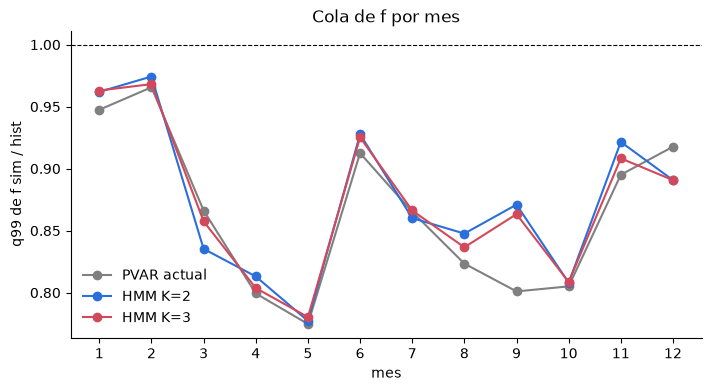

In [6]:
q = [0.5, 0.9, 0.99, 0.999]
tab = {"f histórica": f_hist.quantile(q)}
am = {"f histórica": f_hist.groupby(f_hist.index.year).max().mean()}
for nom, fs in f_sims.items():
    tab[nom] = pd.concat([f_.quantile(q) for f_ in fs], axis=1).median(axis=1)
    am[nom] = np.mean([f_.groupby(f_.index.year).max().mean() for f_ in fs])
tab = pd.DataFrame(tab)
tab.loc["máx. anual medio"] = pd.Series(am)
display(tab.round(3))

#### q99 de f por mes, ratio sim/hist
q99_h = f_hist.groupby(f_hist.index.month).quantile(0.99)
r_mes = {nom: pd.concat(fs).pipe(lambda f_: f_.groupby(f_.index.month).quantile(0.99)) / q99_h for nom, fs in f_sims.items()}
display(pd.DataFrame(r_mes).T.round(2))

fig, ax = plt.subplots(figsize=(7, 3.8), constrained_layout=True)
for (nom, r), col in zip(r_mes.items(), ["0.5", "#2a6fdb", "#d1495b", "#3a9e5f"]):
    ax.plot(r.index, r.values, "o-", color=col, label=nom)
ax.axhline(1, color="k", lw=0.8, ls="--")
ax.set(xlabel="mes", ylabel="q99 de f sim / hist", xticks=range(1, 13), title="Cola de f por mes")
ax.spines[["top", "right"]].set_visible(False); ax.legend(frameon=False)
plt.show()

#### Cómo leerlo
- **Escala por estado** (sección 2): un estado con escala ≫ 1 y poca frecuencia = el régimen "intenso". Si está más presente en primavera/otoño, recoge lo que buscábamos.
- **f**: si los HMM suben el q99, q99.9 y el máx. anual hacia la histórica (1.94 / 2.66 / 2.66), sobre todo en mar–may y sep–nov, el régimen en Σ es la clave → pasar a la cadena completa (08 + 09B).
- **Si no se mueve**: la cola no viene de la escala de los choques sino de la dinámica (persistencia), y haría falta régimen también en los coeficientes.
- Prueba en dos pasos (VAR por MCO + HMM sobre sus innovaciones), no un MS-VAR estimado conjuntamente: suficiente para decidir si merece la pena.